In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### Étape 1 — Chargement et Analyse exploratoire des données

- comprendre la structure générale du jeu de données (types de données, dimensions, aperçus) ;
- Vérifier les valeurs manquantes, les doublons, les incohérences et les valeurs aberrantes. 
- Produire des statistiques descriptives.
- Étudier la distribution de la variable cible et l’éventuel déséquilibre des classes.
- Analyser les relations entre les variables explicatives et la cible.
- Examiner les corrélations entre les variables.
- identifier les variables les plus fortement liées au niveau de risque ;

In [2]:
# Chargement de dataset

df = pd.read_csv('../data/raw/dataset.csv')

In [3]:
# Observation des 5 premiers lignes

df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [4]:
# Observation des 5 derniers lignes

df.tail()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
1995,STU1996,23,Male,2,7.5,20.3,1.89,7.3,10.7,High,8.2,6.3,80.9,No,Average,No,Medium
1996,STU1997,21,Male,2,6.4,16.8,2.14,4.6,5.8,Moderate,4.6,3.5,76.9,Yes,Poor,No,High
1997,STU1998,19,Female,1,4.5,13.1,2.54,7.5,10.0,Low,6.7,8.1,87.9,Yes,NaN,No,High
1998,STU1999,21,Male,3,8.1,22.3,2.62,4.5,6.6,Moderate,6.5,8.4,100.0,No,Good,No,Low
1999,STU2000,19,Female,3,5.9,23.3,2.56,7.6,11.2,High,7.7,8.9,87.6,No,Average,No,Medium


In [5]:
# Les types des variables

df.dtypes

Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object

In [6]:
# La dimention de dataset

df.ndim

2

In [7]:
# Le Shape(Lignes, Colonnes)  de dataset

df.shape

(2000, 17)

In [8]:
# Un résume de dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [9]:
df.describe().T # Observation : La distribution des données est symetrique et suit la loi normal, car la moyenne egal appriximativement à la mediane.

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


##### Nous Observant que il ya des valeurs manqauntes dans ,Sleep_Hours, GPA, Social_Media_Hours, Financial_Stress, Family_Support, Attendance_Rate
##### => Comme decision  : Imputer les valeurs numériques par la median, et les valeurs catégoriels par la valeur la plus fréquence.

In [10]:
df.isna().sum()

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

##### Nous observant que il n'y a pas de lignes dupliqués

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.describe(include="object")

C:\Users\Youcode\AppData\Local\Temp\ipykernel_5324\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Student_ID,Gender,Physical_Activity,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
count,2000,2000,2000,2000,1931,2000,2000
unique,2000,3,3,2,3,2,3
top,STU0001,Female,Moderate,No,Average,No,High
freq,1,971,906,1289,860,1408,680


In [13]:
data = df.columns.difference(['Mental_Health_Risk', 'Previous_Mental_Health_History', 'Diet_Quality', 'Part_Time_Job', 'Physical_Activity', 'Gender', 'Student_ID'])

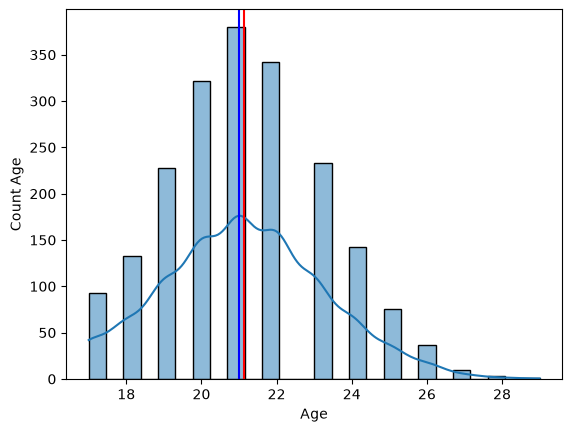

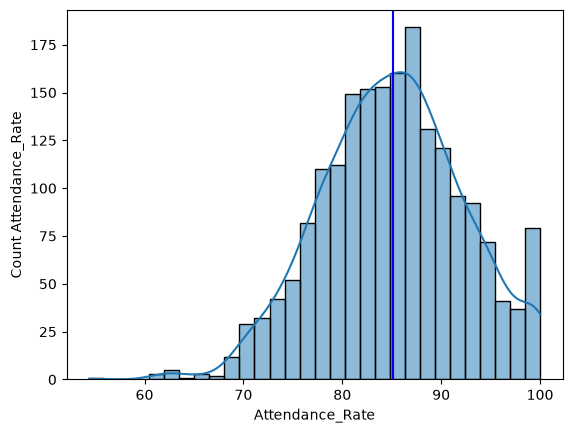

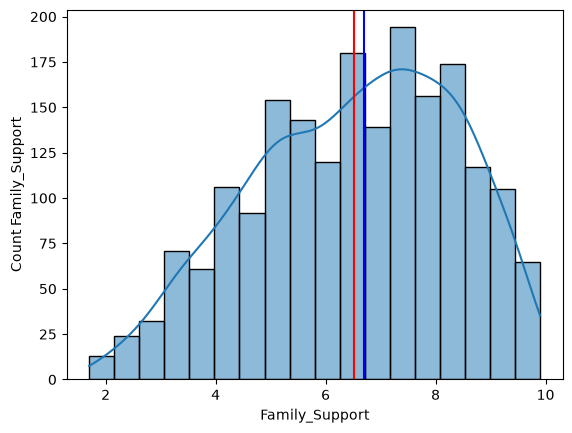

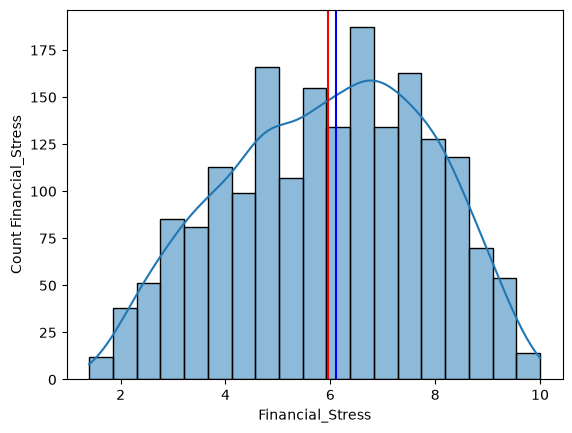

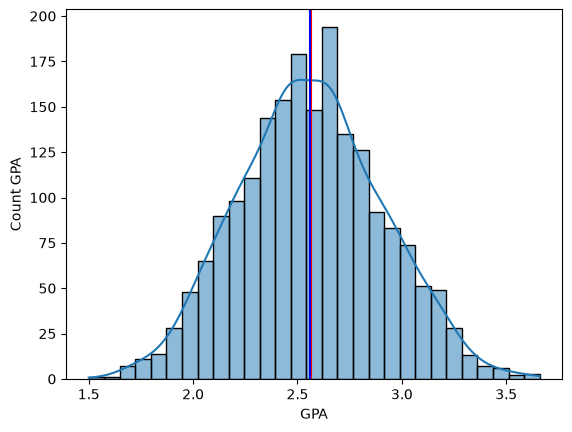

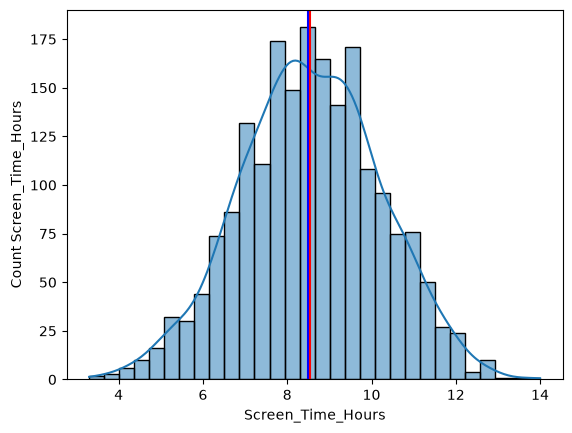

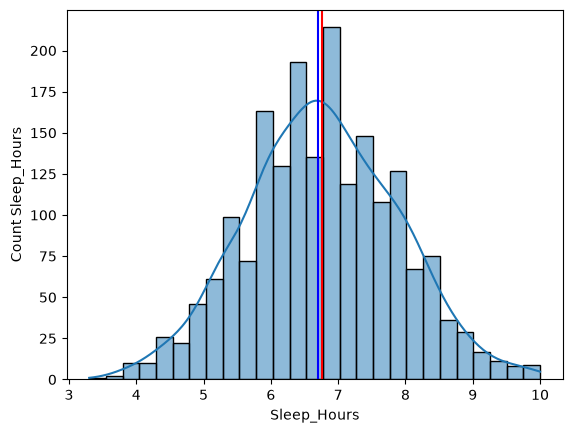

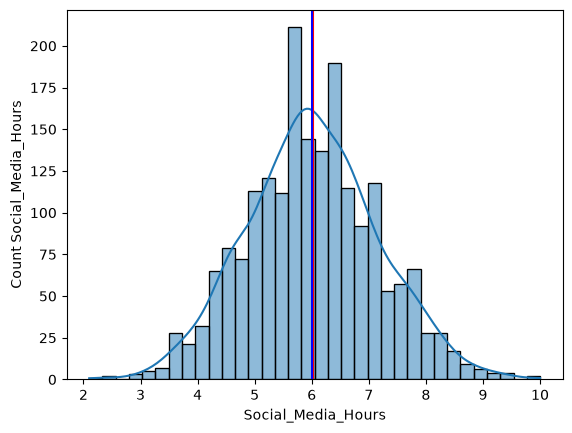

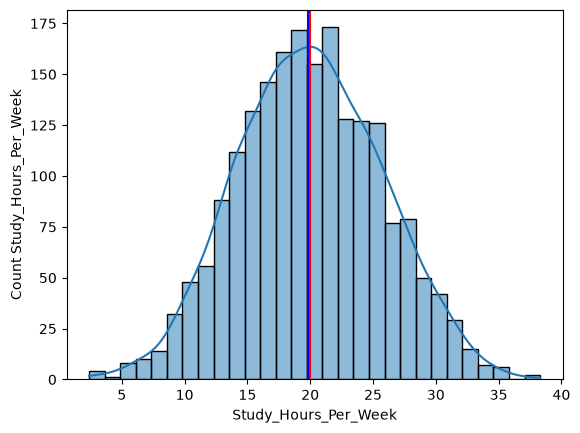

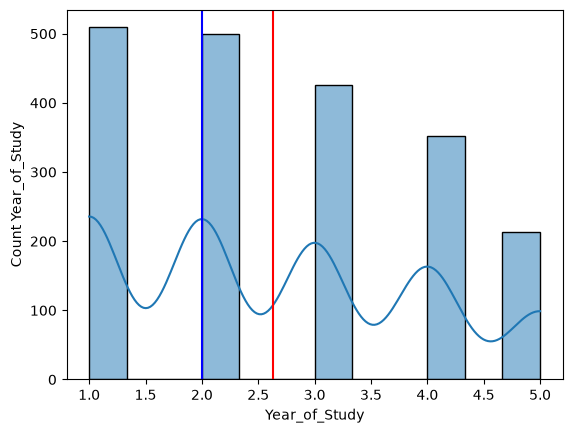

In [14]:
# Visualisation des variables

for col in data:
      sns.histplot(df[col], kde=True)
      plt.axvline(df[col].mean(), c='r')
      plt.axvline(df[col].median(), c='b')
      plt.xlabel(col)
      plt.ylabel(f"Count {col}")
      plt.show()


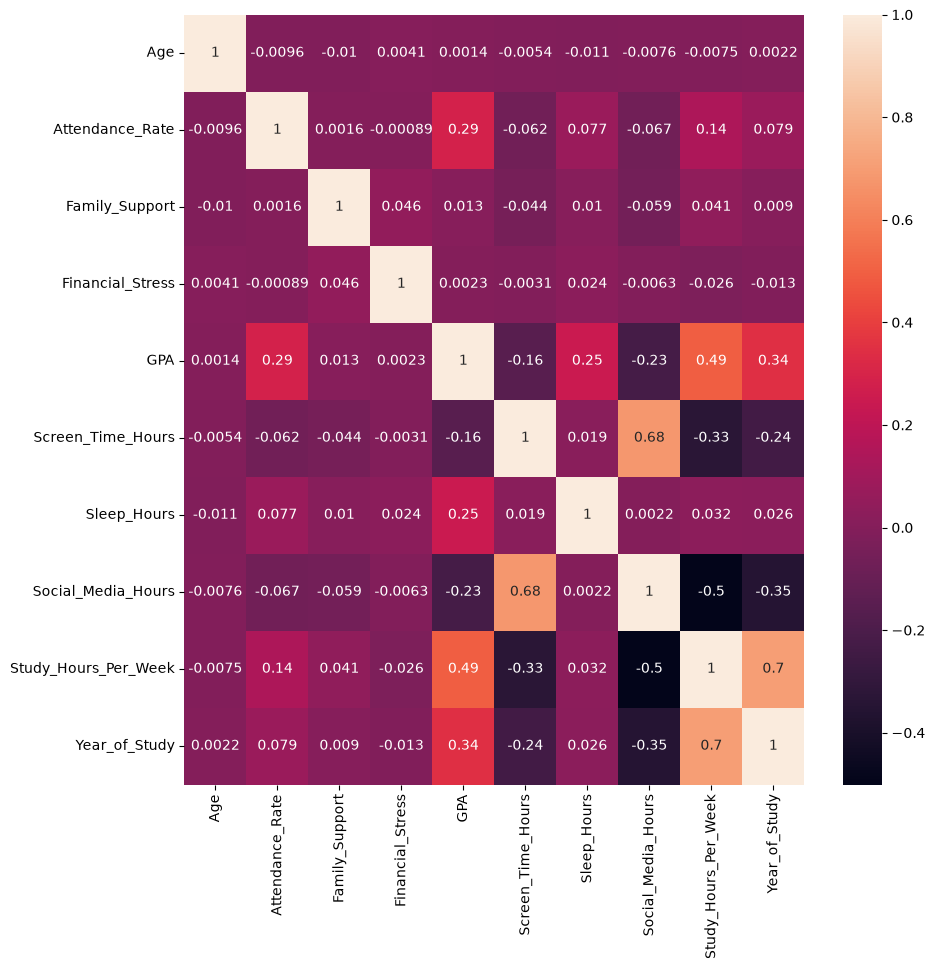

In [15]:
plt.figure(figsize=(10, 10))
sns.heatmap(df[data].corr(), annot=True)
plt.show()
# Nous observant que il ya une relation positive forte entre Year_of_Study et Study_Hours_per_Week
# une relation positive forte entre Screen_time_Hours et Social_Media_Hours 
# une relation positive modérée entre GPA et Study_Hours_per_Week.
#  une relation negative modérée etre Stuy_Hours_per_Week et Social_Media_Hours
# une relation negative Stuy_Hours_per_Week et Screen_time_Hours.

##### Description des colonnes

- GPA : (moyenne pondérée cumulative) la moyenne de tout les points de notes obtenus par un étudiant sur l'ensemble de ses cours, pondérée par le nombre de credits(heures) de chaque matiére.
- Studiant_ID : Identifiant Unique d'un étudiant.
- Age : Age d'un etudiant en années
- Gender : Sexe de l'étudiant(Female, Male, Non-binary)
- Year_of_Study : Année académique actuelle.
- Sleep_Hours : Moyenne d'heures de dormir en nuie
- Study_Hours_Per_Week : Heure d'études par semaine.
- Social_Media_Hours : Moyenne d'heurs d'usage du social media quotidienement.
Screen_Time_Hours : Total d'heure du screen quotidienement.
- Physical_Activity : Frequence des exercices par weekend.
- Financial_Stress : Stress financier ressenti.
- FamilySupport : Score de support de la famille.
- Attendance_Rate : pourcentage de présence.
- Part_Time_Job : emploi à temps partiel or travail à temps partiel.
- Die_Quality : L'auto-evaluation de la qualité du régime alimentaire.
- Previous_Mental_Health_History : Maladie mental diagnistiquée anterieurement.
- Mental_Health_Risk : level de risk prédicté.

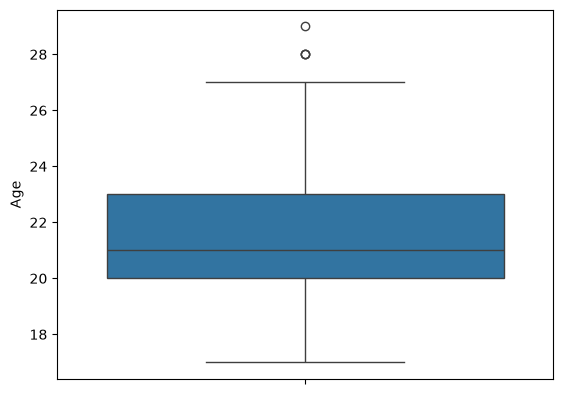

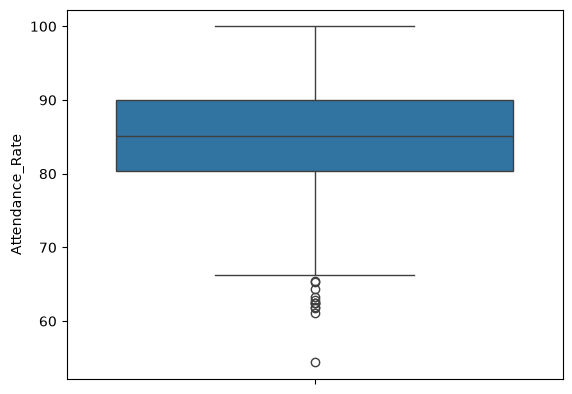

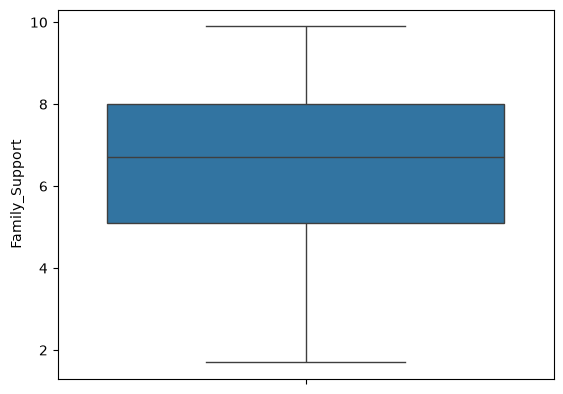

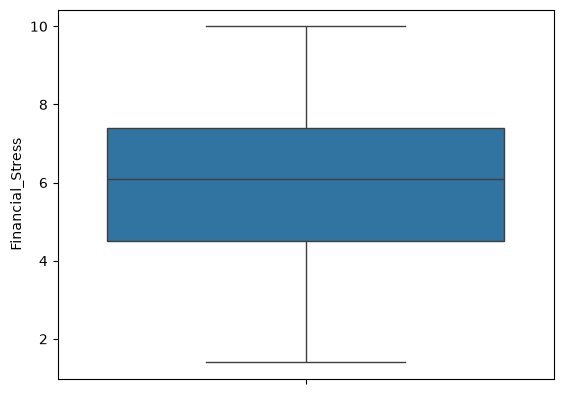

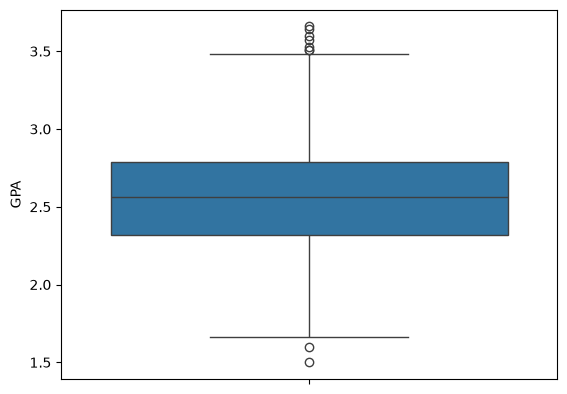

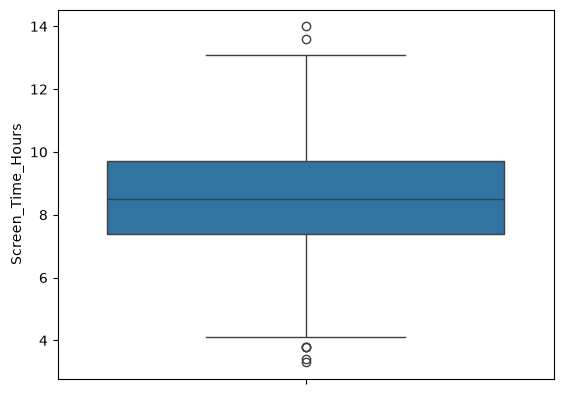

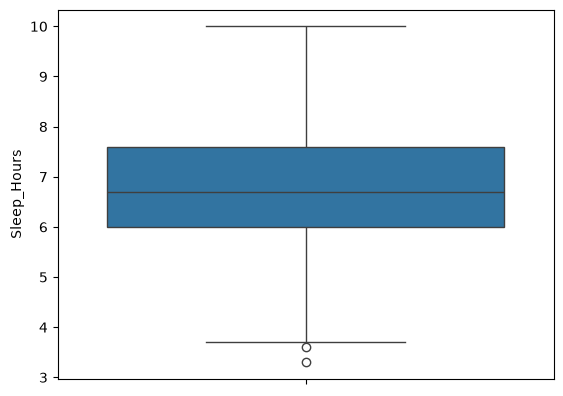

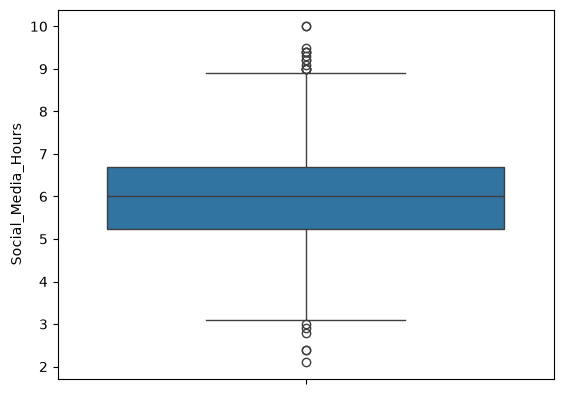

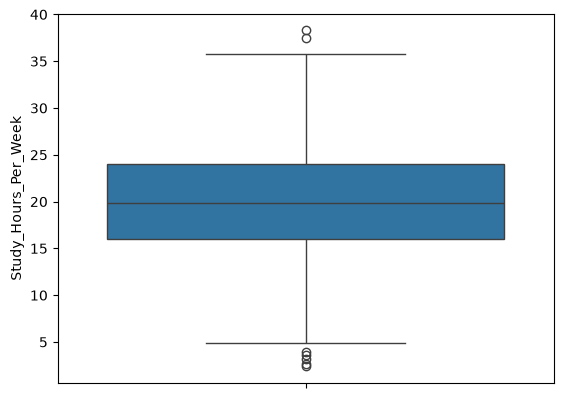

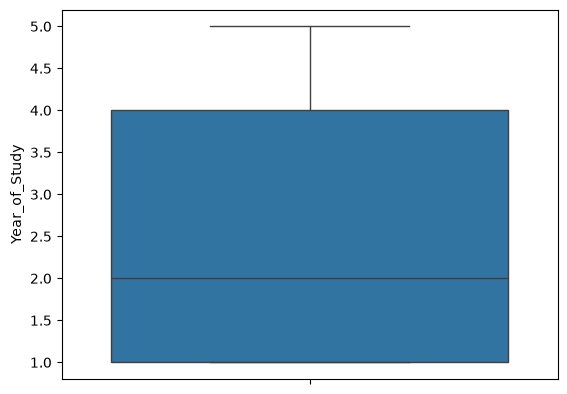

In [16]:
for col in data:
      sns.boxplot(df[col])
      plt.show()

# Nous obsetvant que il ya des valeurs abérants pour Age, Attendance_Rate, GPA, Screen_Time_Hours, Sleep_Hours, Social_Media_Hours, Study_Hours_Per_Week, mais ces valeurs sont possibles.
# => Comme Decision utilisaiton de IQR Clipper

#### Visualisaiton de La distribution des variables continues

In [17]:
target = 'Mental_Health_Risk'
counts = df[target].value_counts()
pourcentages = df[target].value_counts(normalize=True) * 100

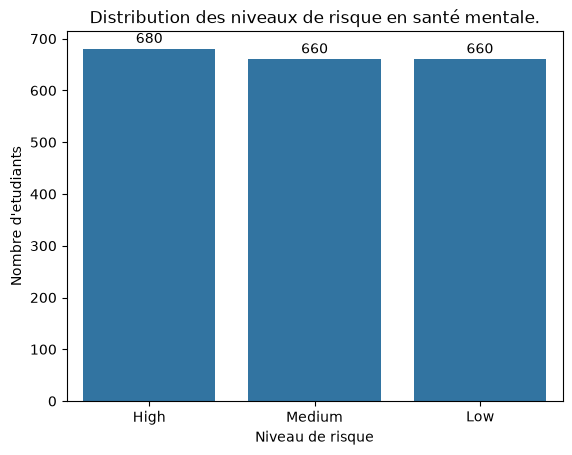

Nombre d'etudiants pour chaque classe : Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


In [18]:
ax = sns.countplot(data=df, x=target, order=counts.index)
ax.bar_label(ax.containers[0], fmt='%d', padding=2)
plt.title('Distribution des niveaux de risque en santé mentale.')
plt.xlabel('Niveau de risque')
plt.ylabel("Nombre d'etudiants")
plt.show()
print(f"Nombre d'etudiants pour chaque classe : {counts}")

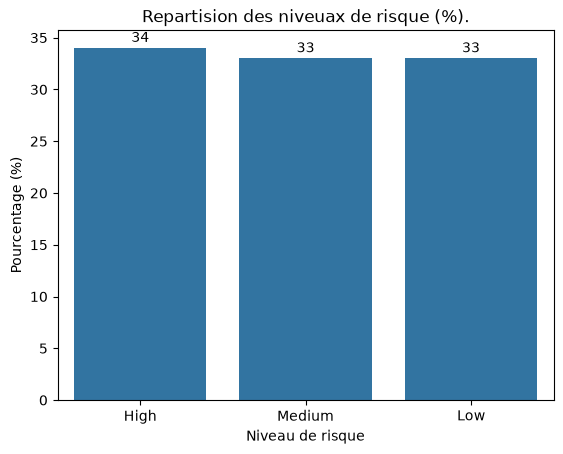

Nombre d'etudiants pour chaque classe : Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64


In [19]:
ax = sns.barplot(x=pourcentages.index, y=pourcentages.values)
ax.bar_label(ax.containers[0], fmt='%d', padding=2)
plt.title('Repartision des niveuax de risque (%).')
plt.xlabel('Niveau de risque')
plt.ylabel("Pourcentage (%)")
plt.show()
print(f"Nombre d'etudiants pour chaque classe : {pourcentages}")


#### Rapport entre la classe majoritaire et minoritaire

In [20]:
imbalenced_ratio = counts.max() / counts.min()
print(f'Imbalenced ratio : {imbalenced_ratio:.2f}')
# La classe majoritaire contient une fois plus d'observations que la classe minoritaire.
# d'apres les effectifs Cela signifie que la classe majoritaire (High) contient seulement environ 3 % d'observations de plus que la classe minoritaire (Low et Medium).

Imbalenced ratio : 1.03


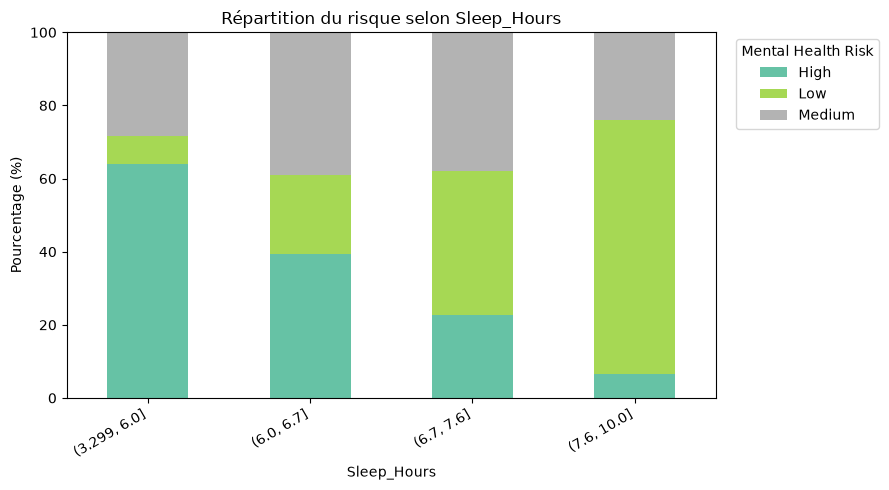

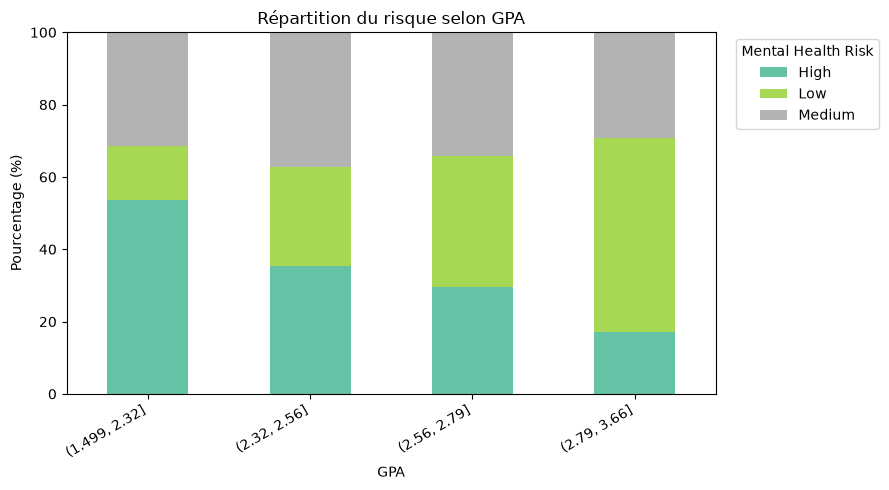

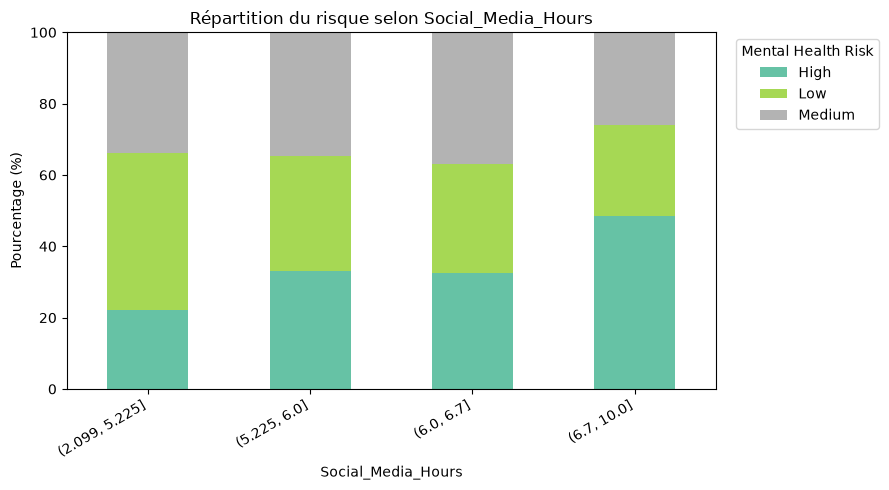

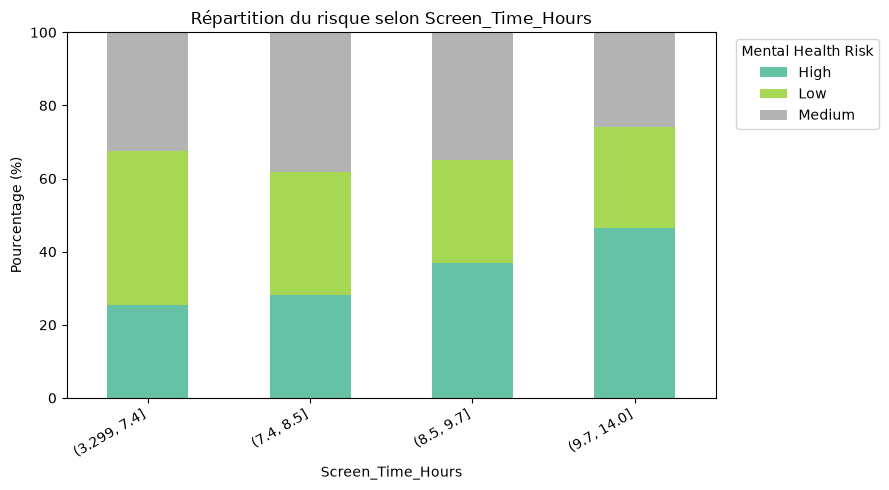

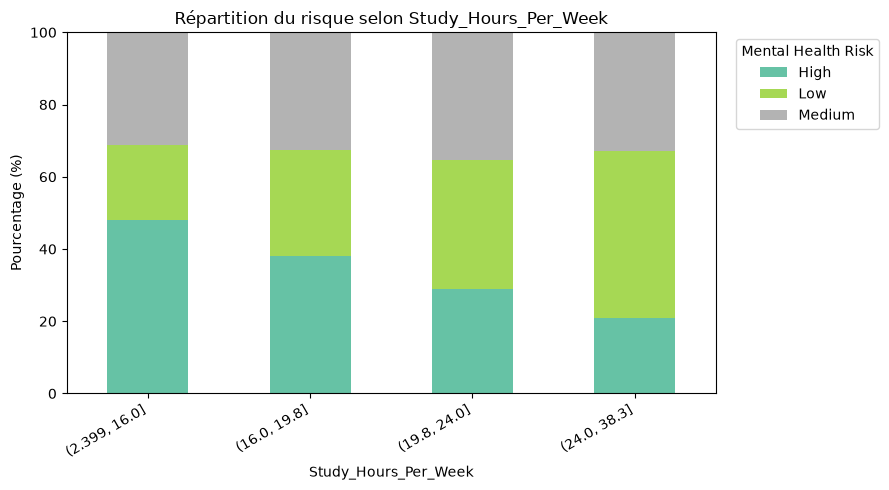

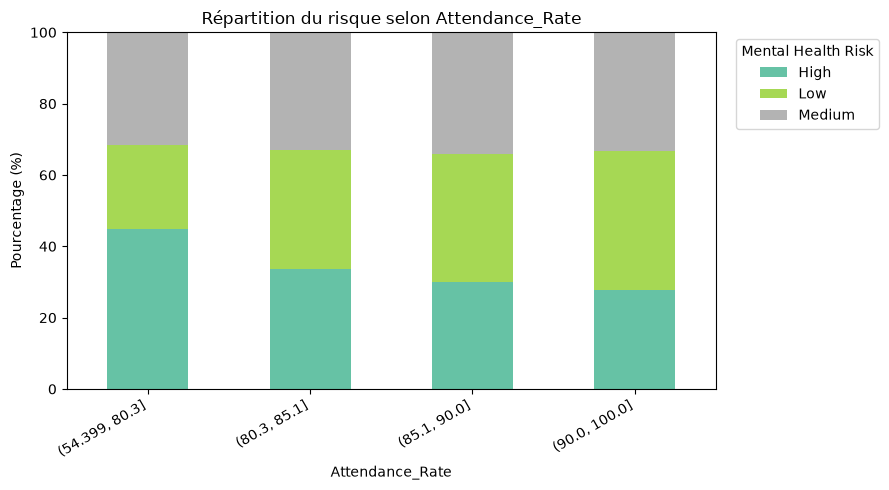

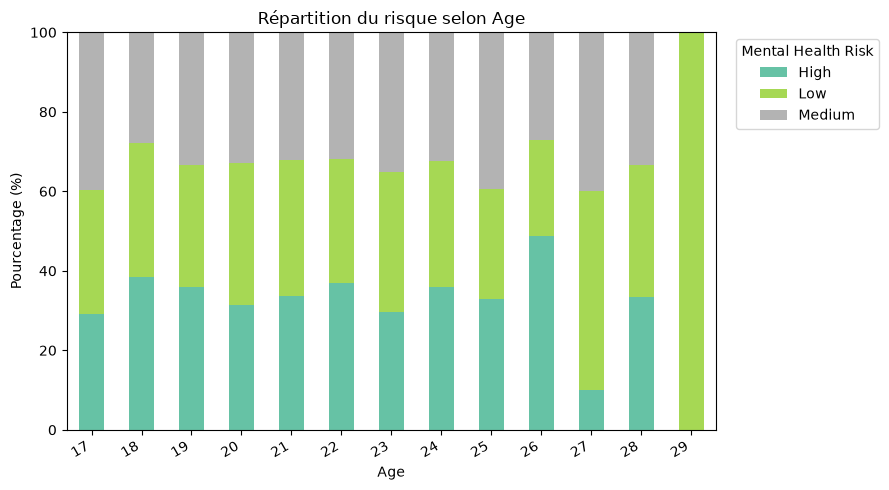

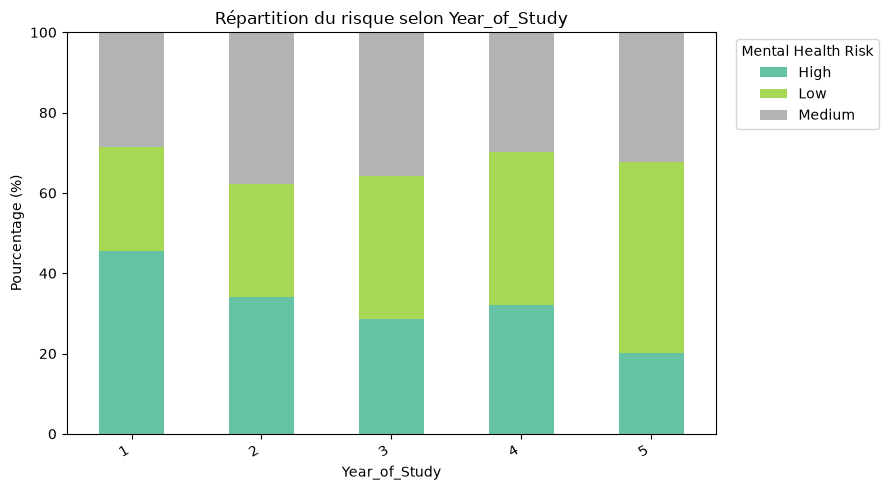

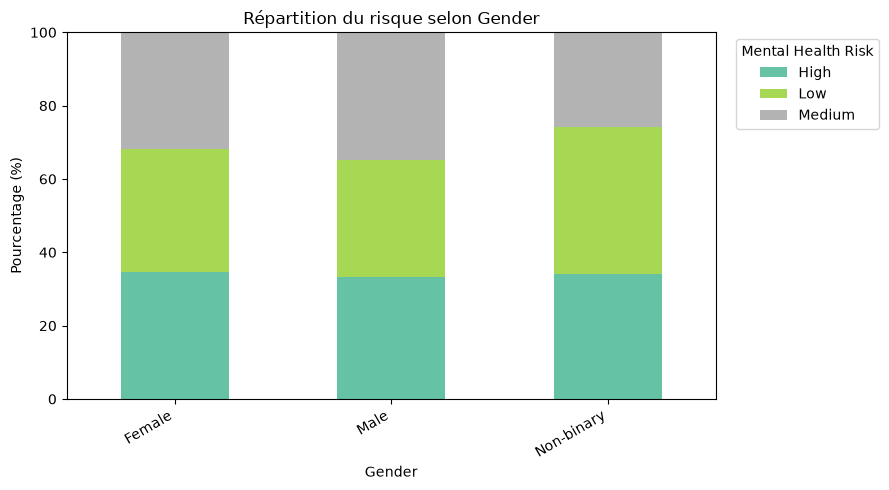

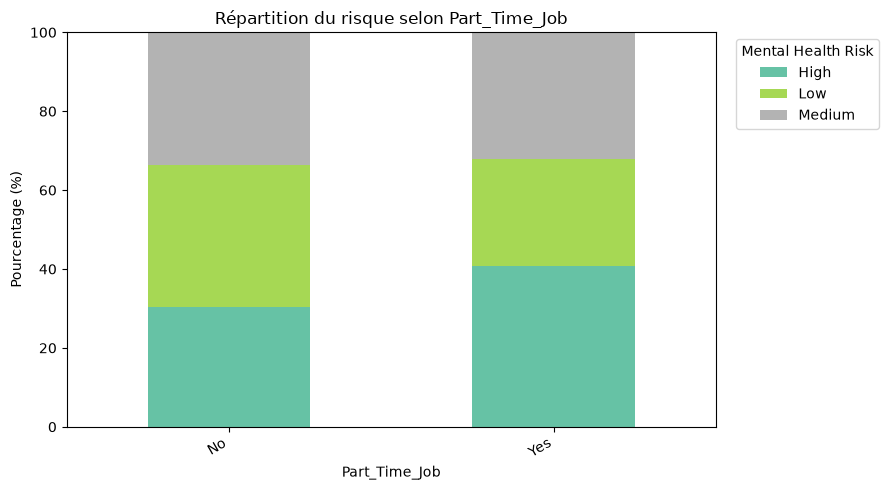

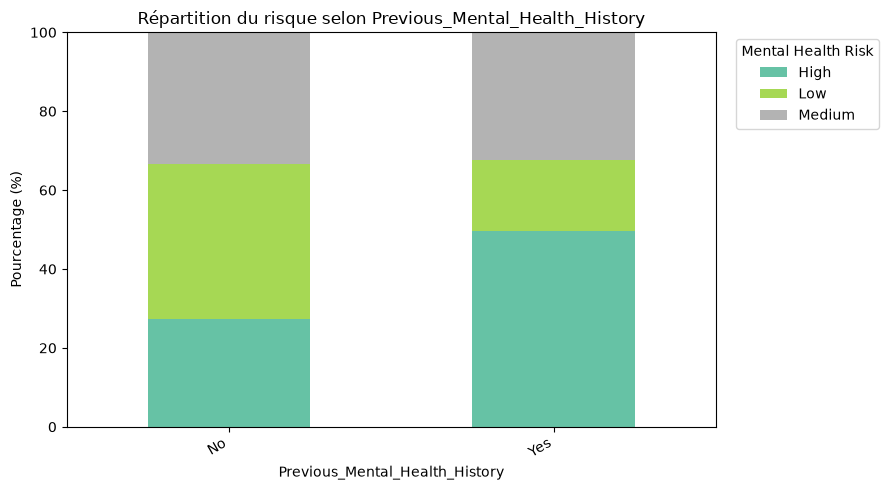

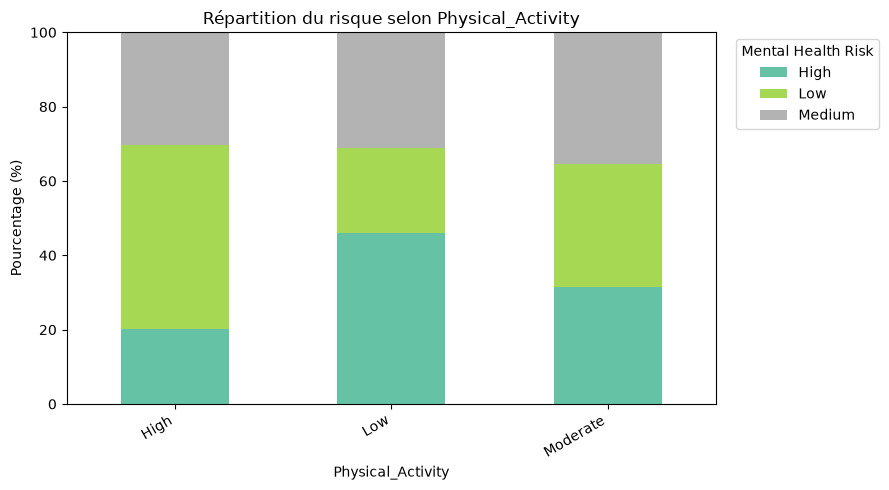

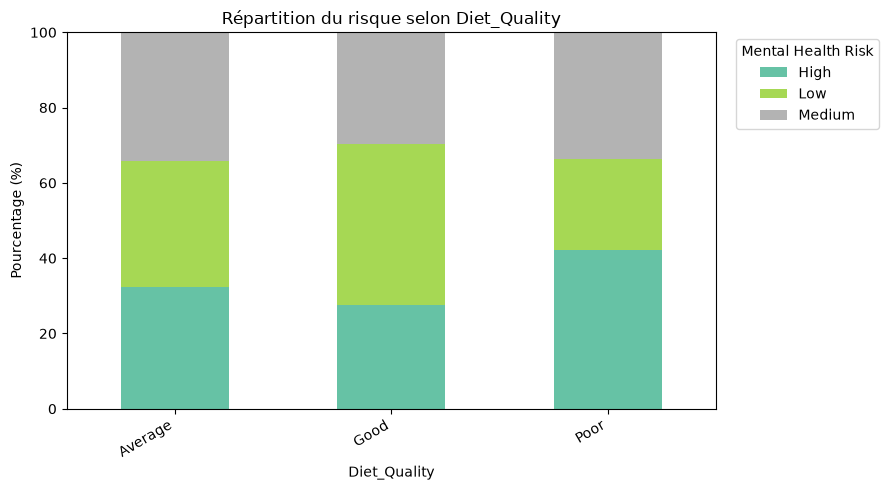

In [21]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Définition des variables
continuous_cols = [
      'Sleep_Hours',
      'GPA',
      'Social_Media_Hours',
      'Screen_Time_Hours',
      'Study_Hours_Per_Week',
      'Attendance_Rate'
]

discrete_cols = [
      'Age',
      'Year_of_Study',
      # 'Financial_Stress',
      # 'Family_Support'
]

categorical_cols = [
      'Gender',
      'Part_Time_Job',
      'Previous_Mental_Health_History',
      'Physical_Activity',
      'Diet_Quality'
]

# 2. Fonction de visualisation
def plot_risk_distribution(df, col, target, bins=None):

      data = df[[col, target]].dropna().copy()

      # Créer les groupes uniquement pour les variables continues
      if bins is not None:
            data['Group'] = pd.qcut(
                  data[col],
                  q=bins,
                  duplicates='drop'
            )
            x_col = 'Group'
      else:
            x_col = col

      # Calcul des proportions par groupe
      portions = pd.crosstab(
            data[x_col],
            data[target],
            normalize='index'
      ).mul(100)

      # Visualisation
      ax = portions.plot(
            kind='bar',
            stacked=True,
            figsize=(9, 5),
            colormap='Set2'
      )

      ax.set_title(f'Répartition du risque selon {col}')
      ax.set_xlabel(col)
      ax.set_ylabel('Pourcentage (%)')
      ax.legend(title='Mental Health Risk', bbox_to_anchor=(1.02, 1))
      ax.set_ylim(0, 100)

      plt.xticks(rotation=30, ha='right')
      plt.tight_layout()
      plt.show()


# 3. Variables continues : création de 4 bins
for col in continuous_cols:
      plot_risk_distribution(
            df,
            col,
            target,
            bins=4
      )


# 4. Variables discrètes et catégorielles
for col in discrete_cols + categorical_cols:
      plot_risk_distribution(
            df,
            col,
            target
      )


In [22]:
# Incohérences métier entre les variables Social Media Hours vs Screen Time Hours car il ya 37 lignes des etudiants qui ont Social_Media_Hours > Screen_Time_Hours
# => Decision clipper les deux valeurs, ou bien les supprimer
inconsistants_screen = df[
      df['Social_Media_Hours'] > df['Screen_Time_Hours']
]
display(inconsistants_screen.shape)
# tmp = inconsistants_screen['Social_Media_Hours']
# inconsistants_screen['Social_Media_Hours'] = inconsistants_screen['Screen_Time_Hours']
# inconsistants_screen['Screen_Time_Hours'] = tmp
# inconsistants_screen[
#       inconsistants_screen['Social_Media_Hours'] > inconsistants_screen['Screen_Time_Hours']
# ]

(37, 17)

#### Étape 2 — Transformation et préparation des données

- Diviser les données en deux ensembles : un ensemble d’entraînement (80 %) et un ensemble de test (20 %).
- Traiter les valeurs manquantes en choisissant la méthode d’imputation la plus adaptée à la nature des données
- Détecter et traiter les valeurs aberrantes en utilisant une méthode appropriée (IQR, Z-score, etc.).
- Encoder les variables catégorielles afin de les convertir en valeurs numériques
- Gérer le déséquilibre des classes avec des techniques de sur-échantillonnage ou sous-échantillonnage (Smote), si nécessaire. 
- Normaliser ou standardiser les variables numériques afin de les mettre à la même échelle.
- Regrouper les transformations dans un pipeline afin d’éviter le data leakage. 
- Chaque décision de nettoyage doit être justifiée.

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline

In [24]:
df_clean = df.copy()
df_clean

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,STU1996,23,Male,2,7.5,20.3,1.89,7.3,10.7,High,8.2,6.3,80.9,No,Average,No,Medium
1996,STU1997,21,Male,2,6.4,16.8,2.14,4.6,5.8,Moderate,4.6,3.5,76.9,Yes,Poor,No,High
1997,STU1998,19,Female,1,4.5,13.1,2.54,7.5,10.0,Low,6.7,8.1,87.9,Yes,NaN,No,High
1998,STU1999,21,Male,3,8.1,22.3,2.62,4.5,6.6,Moderate,6.5,8.4,100.0,No,Good,No,Low


In [25]:
df_clean = df_clean.drop(["Student_ID"], axis=1)

In [26]:
df_clean = df_clean[
      df_clean['Social_Media_Hours'] < df_clean['Screen_Time_Hours']
]

In [27]:
X = df_clean.drop(columns=['Mental_Health_Risk'])
y = df_clean['Mental_Health_Risk']

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1517, 15), (380, 15), (1517,), (380,))

In [29]:
numerics_columns = X.select_dtypes(include='number').columns
numerics_columns
# categorical_columns = X.select_dtypes(include=['object', 'category', 'string']).columns
# categorical_columns
# taile

Index(['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
       'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate'],
      dtype='str')

In [30]:
nominals_columns = [
      'Gender',
      'Part_Time_Job',
      'Previous_Mental_Health_History'
]

ordinals_columns = [
      'Physical_Activity',
      'Diet_Quality'
]
Physical_Activity_column = ['Physical_Activity']
Diet_Quality_column = ['Diet_Quality']

In [31]:
from sklearn.base import BaseEstimator, TransformerMixin

class IQRClipper(BaseEstimator, TransformerMixin):
      def __init__(self, factor=1.5):
            self.factor = factor


      def fit(self, X, y=None):
            self.q1 = np.percentile(X, 25, axis=0)
            self.q3 = np.percentile(X, 75, axis=0)
            self.IQR = self.q3 - self.q1
            self.lower_bound_  = self.q1-(self.factor * self.IQR)
            self.upper_bound_ = self.q3 + (self.factor * self.IQR)
            return self

      def transform(self, X, y=None):
            X = np.asarray(X)
            X_clipped = np.clip(
                  X,
                  self.lower_bound_,
                  self.upper_bound_
            )

            return X_clipped


In [32]:
# numerics_transformers = Pipeline(steps=[
#       ('imputer', SimpleImputer(strategy='median')),
#       ('iqr_clipper', IQRClipper()),
#       ('scaler', StandardScaler(with_mean=False))
# ])

In [33]:
# nominals_transformers = Pipeline(steps=[
#       ('imputer', SimpleImputer(strategy='most_frequent')),
#       ('on_hot_encoder', OneHotEncoder()),
# ])

In [34]:
# Physical_Activity_transformers = Pipeline(steps=[
#       ('imputer', SimpleImputer(strategy='most_frequent')),
#       ('ordinal_encoder', OrdinalEncoder( categories=[['Low', 'Moderate', 'High']])),
# ])

In [35]:
# Diet_Quality_transformers = Pipeline(steps=[
#       ('imputer', SimpleImputer(strategy='most_frequent')),
#       ('ordinal_encoder', OrdinalEncoder(categories=[['Poor', 'Average', 'Good']])),
# ])

In [36]:
# features_preprocessor = ColumnTransformer([
#       ('numerics', numerics_transformers, numerics_columns),
#       ('nominals', nominals_transformers, nominals_columns),
#       ('Physical_Activity', Physical_Activity_transformers, Physical_Activity_column),
#       ('Diet_Quality', Diet_Quality_transformers, Diet_Quality_column)
#       ],
#       remainder='drop'
# )

In [37]:
def create_preprocess(scaling=True):
      numerics_steps= [
                  ('imputer', SimpleImputer(strategy='median')),
                  ('iqr_clipper', IQRClipper()),
                  
            ]
      if scaling:
            numerics_steps.append(
                  ('scaler', StandardScaler(with_mean=False))
            )

      numerics_transformers = Pipeline(steps=numerics_steps)

      nominals_transformers = Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('on_hot_encoder', OneHotEncoder()),
      ])

      Physical_Activity_transformers = Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ordinal_encoder', OrdinalEncoder( categories=[['Low', 'Moderate', 'High']])),
      ])

      Diet_Quality_transformers = Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ordinal_encoder', OrdinalEncoder(categories=[['Poor', 'Average', 'Good']])),
      ])

      features_preprocessor = ColumnTransformer([
            ('numerics', numerics_transformers, numerics_columns),
            ('nominals', nominals_transformers, nominals_columns),
            ('Physical_Activity', Physical_Activity_transformers, Physical_Activity_column),
            ('Diet_Quality', Diet_Quality_transformers, Diet_Quality_column)
            ],
            remainder='drop'
      )

      return features_preprocessor

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from imblearn.over_sampling import SMOTE
# import xgboost as xgb
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
from xgboost import XGBClassifier

In [39]:
models = {
      "LogisticRegression" : (LogisticRegression(max_iter=1000, random_state=42), None, True),
      "DecisionTreeClassifier" : (DecisionTreeClassifier(max_depth=10, random_state=42), None, False),
      "RandomForestClassifier" : (RandomForestClassifier(n_estimators=10, max_depth=10, random_state=42), None, False),
      "SVC" : (SVC(kernel='rbf', probability=True), None, True)
}

LogisticRegression ['High' 'Low' 'Medium']


<Figure size 600x500 with 0 Axes>

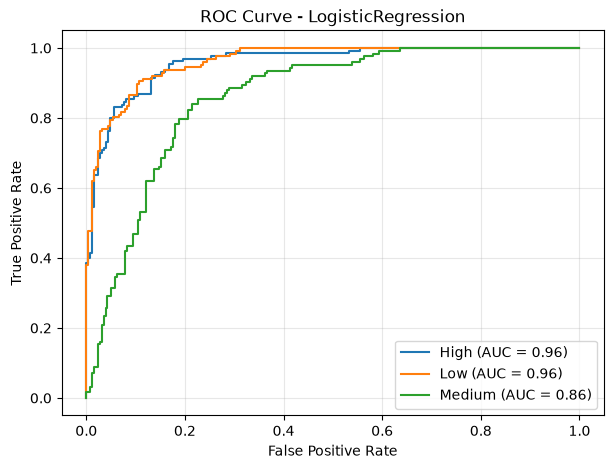

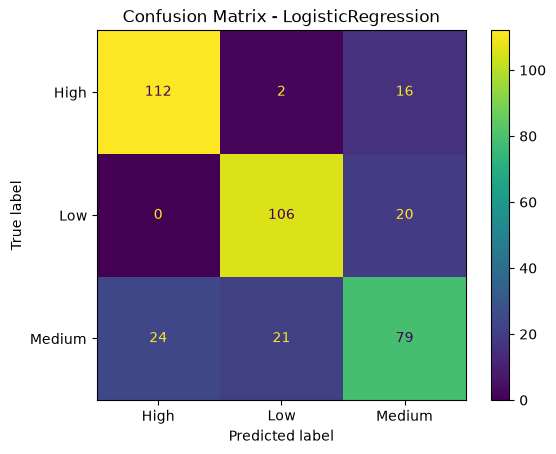

              precision    recall  f1-score   support

        High       0.82      0.86      0.84       130
         Low       0.82      0.84      0.83       126
      Medium       0.69      0.64      0.66       124

    accuracy                           0.78       380
   macro avg       0.78      0.78      0.78       380
weighted avg       0.78      0.78      0.78       380

DecisionTreeClassifier ['High' 'Low' 'Medium']


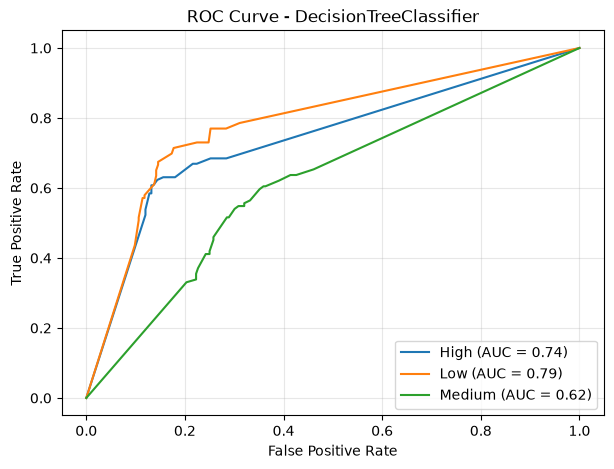

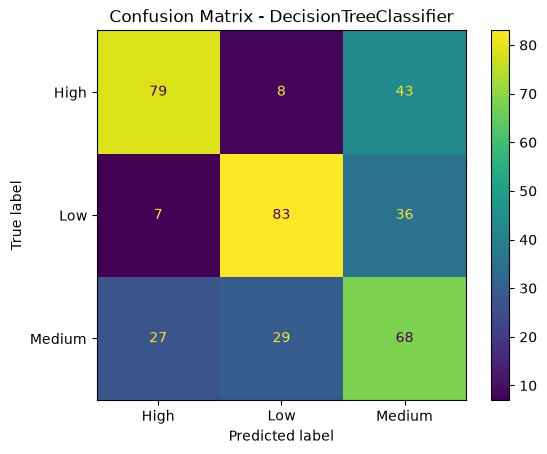

              precision    recall  f1-score   support

        High       0.70      0.61      0.65       130
         Low       0.69      0.66      0.67       126
      Medium       0.46      0.55      0.50       124

    accuracy                           0.61       380
   macro avg       0.62      0.60      0.61       380
weighted avg       0.62      0.61      0.61       380

RandomForestClassifier ['High' 'Low' 'Medium']


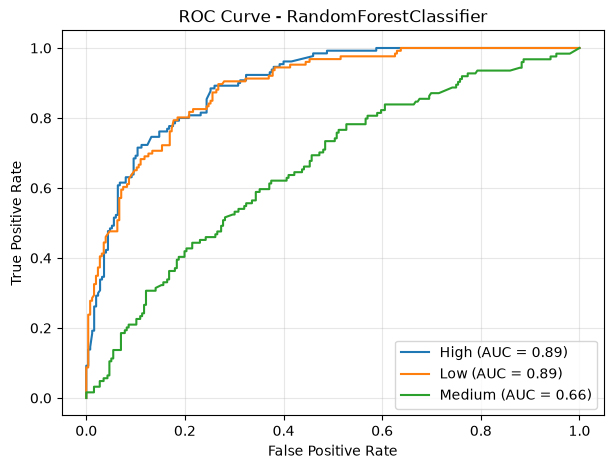

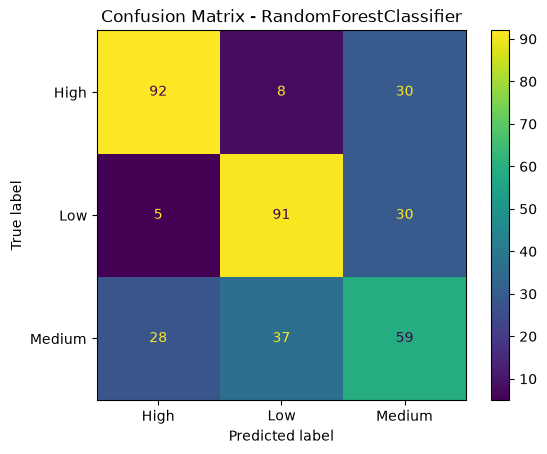

              precision    recall  f1-score   support

        High       0.74      0.71      0.72       130
         Low       0.67      0.72      0.69       126
      Medium       0.50      0.48      0.49       124

    accuracy                           0.64       380
   macro avg       0.63      0.64      0.63       380
weighted avg       0.64      0.64      0.64       380



c:\Users\Youcode\Documents\DEVAI\Student_Mental_Health\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVC ['High' 'Low' 'Medium']


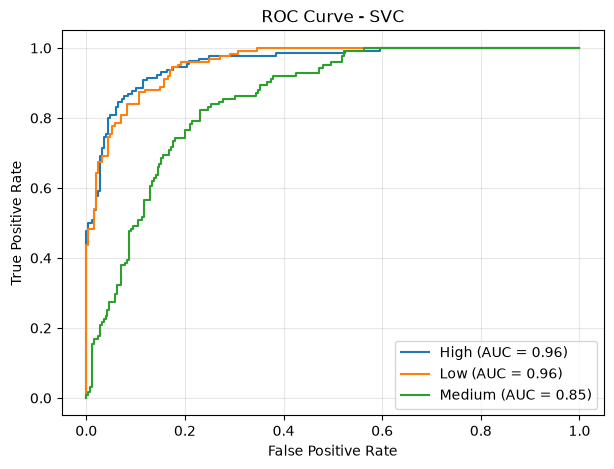

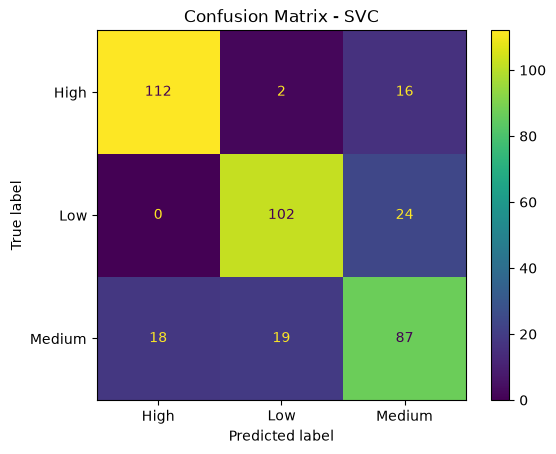

              precision    recall  f1-score   support

        High       0.86      0.86      0.86       130
         Low       0.83      0.81      0.82       126
      Medium       0.69      0.70      0.69       124

    accuracy                           0.79       380
   macro avg       0.79      0.79      0.79       380
weighted avg       0.79      0.79      0.79       380



,model_name,model,accuracy,recall_macro,f1_macro,roc_auc_macro,auc_low,auc_medium,auc_high
0,LogisticRegression,"Pipeline(steps=[('preproces',\n ...",0.781579,0.779968,0.778189,0.927211,0.962661,0.860604,0.958369
1,SVC,"Pipeline(steps=[('preproces',\n ...",0.792105,0.790892,0.791348,0.923414,0.957630,0.854335,0.958277
2,RandomForestClassifier,"Pipeline(steps=[('preproces',\n ...",0.636842,0.635240,0.633941,0.814376,0.888826,0.659747,0.894554
3,DecisionTreeClassifier,"Pipeline(steps=[('preproces',\n ...",0.605263,0.604937,0.608949,0.714998,0.785355,0.618700,0.740938


In [40]:
from sklearn.preprocessing import label_binarize

results = []

# Ordre des classes
classes = ['High', 'Low', 'Medium']

# Transformer y_test en représentation binaire

plt.figure(figsize=(6,5))

colors = ['orange','red','green']
for model_name, (model, params, scaling) in models.items():

      features_preprocessor = create_preprocess(scaling=scaling)
      
      pipe = Pipeline([
      ('preproces', features_preprocessor),
      # ('smote', SMOTE(random_state=42)),
      ('classificator', model)
      ])
      pipe.fit(X_train, y_train)
      y_test_bin = label_binarize(y_test, classes=pipe.classes_)

      y_pred = pipe.predict(X_test)
      # Probabilités pour chaque classe
      y_score = pipe.predict_proba(X_test)
      
      # Vérification de l'ordre des classes
      print(model_name, pipe.classes_)
      
      # Calcul du ROC-AUC multiclasse
      roc_auc_macro = roc_auc_score(
            y_test,
            y_score,
            labels=pipe.classes_,
            multi_class='ovr',
            average='macro'
      )
      
      # Courbes ROC
      plt.figure(figsize=(7, 5))

      auc_per_class = {}

      for i, class_name in enumerate(pipe.classes_):
      
            fpr, tpr, thresholds = roc_curve(
                  y_test_bin[:, i],
                  y_score[:, i]
            )
      
            auc_value = auc(fpr, tpr)
      
            auc_per_class[class_name] = auc_value
      
            plt.plot(
                  fpr,
                  tpr,
                  label=f'{class_name} (AUC = {auc_value:.2f})'
            )
      
      # Ligne du classificateur aléatoire
      # plt.plot(
      #       [0, 1],
      #       [0, 1],
      #       'k--',
      #       label='Random Guess'
      # )
      
      plt.xlabel('False Positive Rate')
      plt.ylabel('True Positive Rate')
      plt.title(f'ROC Curve - {model_name}')
      plt.legend(loc='lower right')
      plt.grid(alpha=0.3)
      plt.show()

      # Matrice de confusion
      ConfusionMatrixDisplay.from_predictions(
            y_test,
            y_pred,
            labels=pipe.classes_,
            display_labels=pipe.classes_
      )

      plt.title(f'Confusion Matrix - {model_name}')
      plt.show()

      # Rapport de classification
      print(classification_report(y_test, y_pred))

      # Résultats
      results.append({
            'model_name': model_name,
            'model': pipe,
            'accuracy': accuracy_score(y_test, y_pred),
            'recall_macro': recall_score(
                  y_test, y_pred, average='macro'
            ),
            'f1_macro': f1_score(
                  y_test, y_pred, average='macro'
            ),
            'roc_auc_macro': roc_auc_macro,
            'auc_low': auc_per_class['Low'],
            'auc_medium': auc_per_class['Medium'],
            'auc_high': auc_per_class['High']
      })
      
# Comparaison finale
results_df = pd.DataFrame(results).sort_values(
            by='roc_auc_macro',
            ascending=False, ignore_index=True
      )

display(
      results_df
)

In [41]:
# from sklearn.metrics import RocCurveDisplay
# results = []

# # Ordre des classes
# classes = ['Low', 'Medium', 'High']

# # Transformer y_test en représentation binaire
# y_train_bin = label_binarize(y_test, classes=classes)


# plt.figure(figsize=(6,5))

# colors = ['orange','red','green']
# for model_name, (model, params, scaling) in models.items():

#       features_preprocessor = create_preprocess(scaling=scaling)
      
#       pipe = Pipeline([
#       ('preproces', features_preprocessor),
#       ('smote', SMOTE(random_state=42)),
#       ('classificator', model)
#       ])
#       pipe.fit(X_train, y_train)
      
#       y_pred = pipe.predict(X_train)
#       # Probabilités pour chaque classe
#       y_score = pipe.predict_proba( X_test)
      
#       # Vérification de l'ordre des classes
#       print(model_name, pipe.classes_)
      
#       # Calcul du ROC-AUC multiclasse
#       roc_auc_macro = roc_auc_score(
#             y_test,
#             y_score,
#             labels=pipe.classes_,
#             multi_class='ovr',
#             average='macro'
#       )
      
#       # Courbes ROC
#       fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#       auc_per_class = {}

#       for i, class_name in enumerate(pipe.classes_):
      
#             # fpr, tpr, thresholds = roc_curve(
#             #       y_train_bin[:, i],
#             #       y_score[:, i]
#             # )
      
#             # auc_value = auc(fpr, tpr)
      
#             # auc_per_class[class_name] = auc_value
      
#             # plt.plot(
#             #       fpr,
#             #       tpr,
#             #       label=f'{class_name} (AUC = {auc_value:.2f})'
#             # )
#             ax = axes[i]
#             RocCurveDisplay.from_predictions(
#             y_train_bin[:, i],
#             y_score[:, i],
#             name=model_name,
#             ax=ax
#             )

#             ax.plot(
#             [0, 1],
#             [0, 1],
#             linestyle="--",
#             color="gray",
#             label="Random classifier"
#       )

#             ax.set_title(f"ROC Curve - {class_name} vs Rest")
#             ax.legend(loc="lower right")

#       plt.tight_layout()
#       plt.show()

      
#       # Ligne du classificateur aléatoire
#       # plt.plot(
#       #       [0, 1],
#       #       [0, 1],
#       #       'k--',
#       #       label='Random Guess'
#       # )
      
# #       plt.xlabel('False Positive Rate')
# #       plt.ylabel('True Positive Rate')
# #       plt.title(f'ROC Curve - {model_name}')
# #       plt.legend(loc='lower right')
# #       plt.grid(alpha=0.3)
# #       plt.show()

# #       # Matrice de confusion
# #       ConfusionMatrixDisplay.from_predictions(
# #             y_train,
# #             y_pred,
# #             labels=pipe.classes_,
# #             display_labels=pipe.classes_
# #       )

# #       plt.title(f'Confusion Matrix - {model_name}')
# #       plt.show()

# #       # Rapport de classification
# #       print(classification_report(y_train, y_pred))

# #       # Résultats
# #       results.append({
# #             'model_name': model_name,
# #             'model': pipe,
# #             'accuracy': accuracy_score(y_train, y_pred),
# #             'recall_macro': recall_score(
# #                   y_train, y_pred, average='macro'
# #             ),
# #             'f1_macro': f1_score(
# #                   y_train, y_pred, average='macro'
# #             ),
# #             'roc_auc_macro': roc_auc_macro,
# #             'auc_low': auc_per_class['Low'],
# #             'auc_medium': auc_per_class['Medium'],
# #             'auc_high': auc_per_class['High']
# #       })
      
# # # Comparaison finale
# # results_df = pd.DataFrame(results).sort_values(
# #             by='roc_auc_macro',
# #             ascending=False, ignore_index=True
# #       )

# # display(
# #       results_df
# # )

In [42]:
best_model_reference = results_df.iloc[0]['model']
y_test_predict_reference = best_model_reference.predict(X_test)

              precision    recall  f1-score   support

        High       0.82      0.86      0.84       130
         Low       0.82      0.84      0.83       126
      Medium       0.69      0.64      0.66       124

    accuracy                           0.78       380
   macro avg       0.78      0.78      0.78       380
weighted avg       0.78      0.78      0.78       380



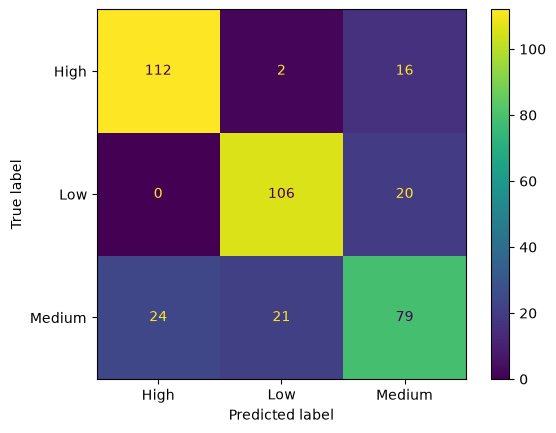

In [43]:
print(classification_report(y_test, y_test_predict_reference))
ConfusionMatrixDisplay.from_predictions(y_test, y_test_predict_reference, labels=classes)
plt.show()

#### Étape 4 — Optimisation et évaluation

In [44]:
from sklearn.model_selection import GridSearchCV

In [45]:
models_with_params = {
      "LogisticRegression" : (
            LogisticRegression(max_iter=100, random_state=42),
            {
                  'classificator__fit_intercept' : [True, False],
                  'classificator__l1_ratio' : [0.0],
                  'classificator__solver': ['saga'],
                  'classificator__max_iter': [10, 50],
            },
            True),
      "DecisionTreeClassifier" : (
      
            DecisionTreeClassifier(random_state=42),
            {
                  'classificator__max_depth': [3, 5, 7, 10, 15, 20, None],
                  'classificator__min_samples_split': [2, 5, 10, 20],
                  'classificator__min_samples_leaf': [1, 2, 5, 10],
                  'classificator__criterion': ["gini", "entropy"]
            },
            False
      ),
      
      "RandomForestClassifier": (
            RandomForestClassifier(random_state=42),
            {
                  'classificator__n_estimators': [100, 200, 300],
                  'classificator__max_depth': [5, 10, 15, 20, None],
                  'classificator__min_samples_split': [2, 5, 10],
                  'classificator__min_samples_leaf': [1, 2, 4, 8],
                  'classificator__max_features': ['sqrt', 'log2'],
                  'classificator__criterion': ['gini', 'entropy']
            },
            False
      ),
      "SVC" : (
            SVC(kernel='linear', probability=True),
            {
                  'classificator__C' : [0.1, 1],
                  'classificator__gamma' : ['scale', 'auto'],
                  'classificator__kernel' : ['linear', 'poly', 'rbf'],
            },
            True
      )
}

LogisticRegression ['High' 'Low' 'Medium']


c:\Users\Youcode\Documents\DEVAI\Student_Mental_Health\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


<Figure size 600x500 with 0 Axes>

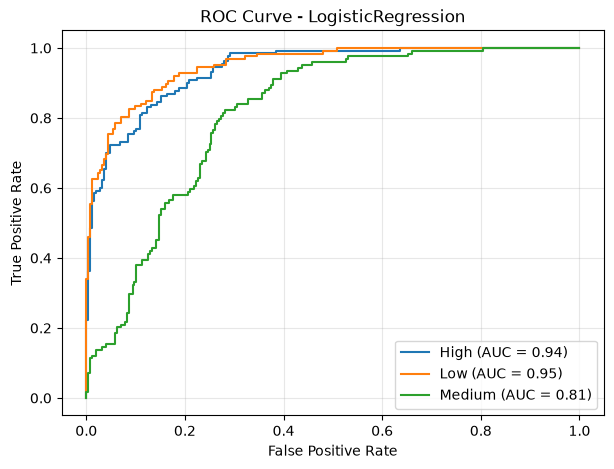

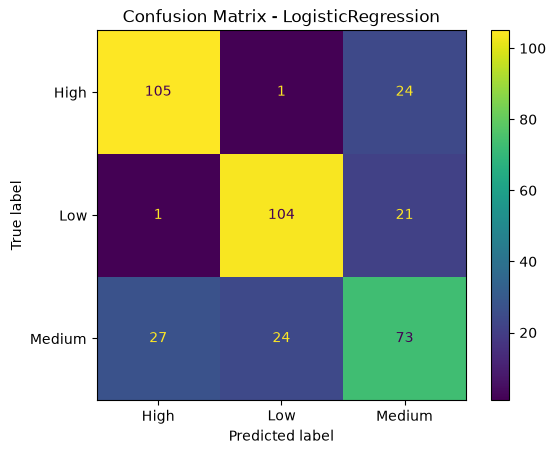

              precision    recall  f1-score   support

        High       0.79      0.81      0.80       130
         Low       0.81      0.83      0.82       126
      Medium       0.62      0.59      0.60       124

    accuracy                           0.74       380
   macro avg       0.74      0.74      0.74       380
weighted avg       0.74      0.74      0.74       380

DecisionTreeClassifier ['High' 'Low' 'Medium']


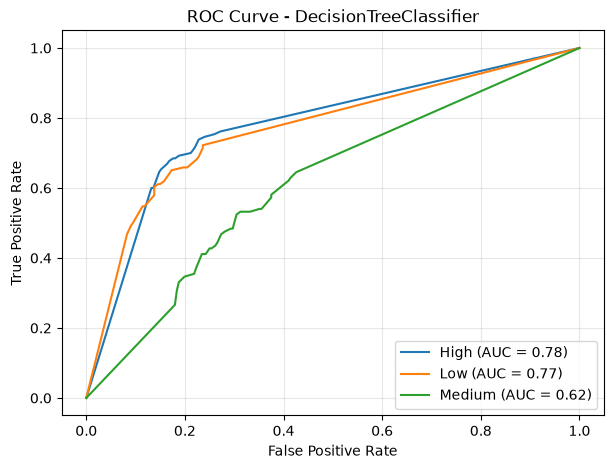

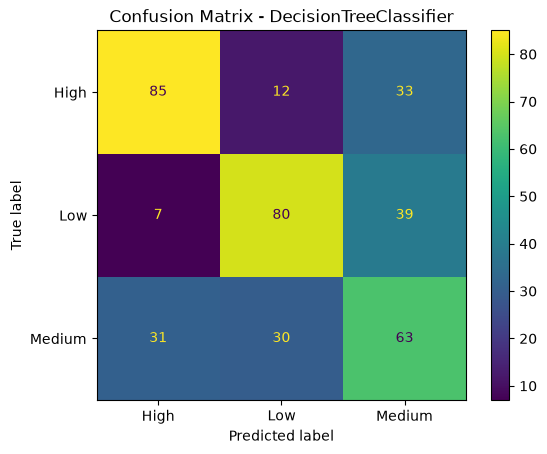

              precision    recall  f1-score   support

        High       0.69      0.65      0.67       130
         Low       0.66      0.63      0.65       126
      Medium       0.47      0.51      0.49       124

    accuracy                           0.60       380
   macro avg       0.60      0.60      0.60       380
weighted avg       0.61      0.60      0.60       380

RandomForestClassifier ['High' 'Low' 'Medium']


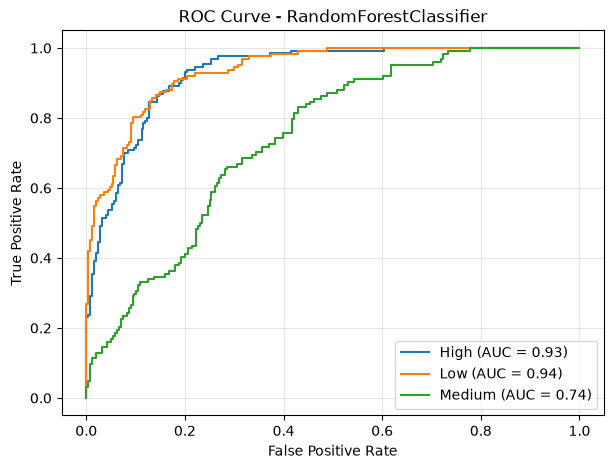

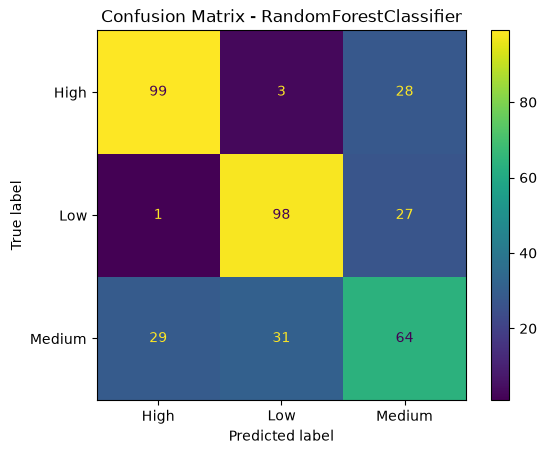

              precision    recall  f1-score   support

        High       0.77      0.76      0.76       130
         Low       0.74      0.78      0.76       126
      Medium       0.54      0.52      0.53       124

    accuracy                           0.69       380
   macro avg       0.68      0.69      0.68       380
weighted avg       0.68      0.69      0.69       380



c:\Users\Youcode\Documents\DEVAI\Student_Mental_Health\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVC ['High' 'Low' 'Medium']


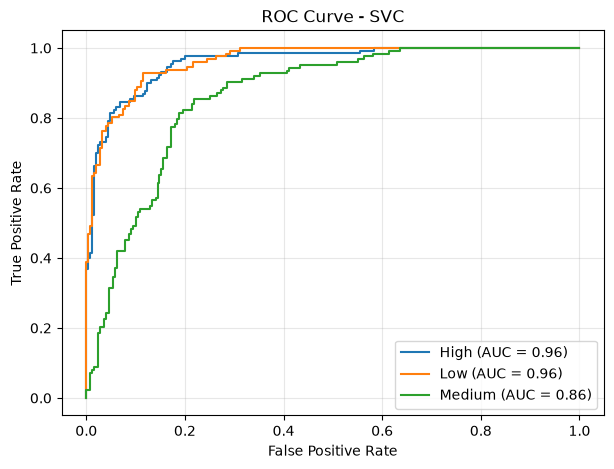

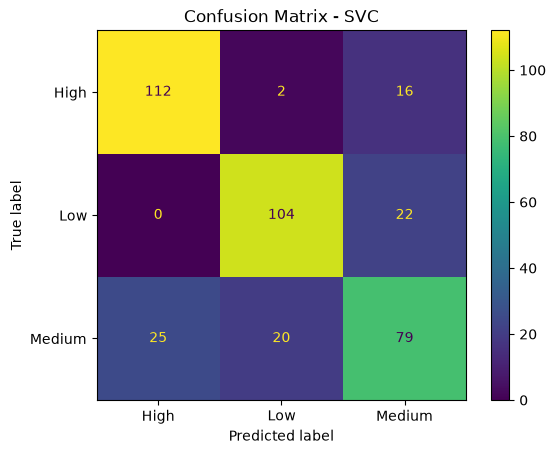

              precision    recall  f1-score   support

        High       0.82      0.86      0.84       130
         Low       0.83      0.83      0.83       126
      Medium       0.68      0.64      0.66       124

    accuracy                           0.78       380
   macro avg       0.77      0.77      0.77       380
weighted avg       0.77      0.78      0.77       380

None


C:\Users\Youcode\AppData\Local\Temp\ipykernel_5324\1091835059.py:107: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  results_Grid_Search_df.sort_values(


In [46]:
results_Grid_Search = []

# Ordre des classes
classes = ['Low', 'Medium', 'High']

# Transformer y_test en représentation binaire
y_test_bin = label_binarize(y_test, classes=classes)

plt.figure(figsize=(6,5))

colors = ['orange','red','green']
for model_name, (model, params, scaling) in models_with_params.items():
      features_preprocessor = create_preprocess(scaling=scaling)
      pipe = Pipeline([
      ('preproces', features_preprocessor),
      # ('smote', SMOTE(random_state=42)),
      ('classificator', model)
      ])

      gs = GridSearchCV(estimator=pipe, param_grid=params, cv=5, scoring='f1_macro', n_jobs=-1)
      gs.fit(X_train, y_train)
      best_estimator = gs.best_estimator_

      y_test_bin = label_binarize(y_test, classes=best_estimator.classes_)
      
      # print(f"{model_name} : {pipeline.score(X_train, y_train)}")
      y_pred = best_estimator.predict(X_test)
      # Probabilités pour chaque classe
      y_score = best_estimator.predict_proba(X_test)
      
      # Vérification de l'ordre des classes
      print(model_name, best_estimator.classes_)
      
      # Calcul du ROC-AUC multiclasse
      roc_auc_macro = roc_auc_score(
            y_test,
            y_score,
            labels=best_estimator.classes_,
            multi_class='ovr',
            average='macro'
      )
      
      # Courbes ROC
      plt.figure(figsize=(7, 5))

      auc_per_class = {}

      for i, class_name in enumerate(best_estimator.classes_):
      
            fpr, tpr, thresholds = roc_curve(
                  y_test_bin[:, i],
                  y_score[:, i]
            )
      
            auc_value = auc(fpr, tpr)
      
            auc_per_class[class_name] = auc_value
      
            plt.plot(
                  fpr,
                  tpr,
                  label=f'{class_name} (AUC = {auc_value:.2f})'
            )

      plt.xlabel('False Positive Rate')
      plt.ylabel('True Positive Rate')
      plt.title(f'ROC Curve - {model_name}')
      plt.legend(loc='lower right')
      plt.grid(alpha=0.3)
      plt.show()

      # Matrice de confusion
      ConfusionMatrixDisplay.from_predictions(
            y_test,
            y_pred,
            labels=best_estimator.classes_,
            display_labels=best_estimator.classes_
      )

      plt.title(f'Confusion Matrix - {model_name}')
      plt.show()

      # Rapport de classification
      print(classification_report(y_test, y_pred))

      # Résultats
      results_Grid_Search.append({
            'model_name': model_name,
            'model' : best_estimator,
            'accuracy': accuracy_score(y_test, y_pred),
            'recall_macro': recall_score(
                  y_test, y_pred, average='macro'
            ),
            'f1_macro': f1_score(
                  y_test, y_pred, average='macro'
            ),
            'roc_auc_macro': roc_auc_macro,
            'auc_low': auc_per_class['Low'],
            'auc_medium': auc_per_class['Medium'],
            'auc_high': auc_per_class['High']
      })

# Comparaison finale
results_Grid_Search_df = pd.DataFrame(results_Grid_Search)

print(
      results_Grid_Search_df.sort_values(
            by='roc_auc_macro',
            ascending=False, ignore_index=True, inplace=True
      )
)

- ROC (Receiver Operating Characteristic) : une courbe qui montre le comportement d'un classificateur lorsqu'on change le seuil de décision.

- AUC (Area Under the Curve) : la surface située sous cette courbe.

In [47]:
y_test_predict = results_Grid_Search_df.iloc[0]['model'].predict(X_test)
results_Grid_Search_df.iloc[0]['model']

,steps,"[('preproces', ...), ('classificator', ...)]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[object](3,)","['High','Low','Medium']"
feature_names_in_,"ndarray[object](15,)","['Age','Gender','Year_of_Study',...,'Part_Time_Job','Diet_Quality', 'Previous_Mental_Health_History']"
n_features_in_,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerics', ...), ('nominals', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


              precision    recall  f1-score   support

        High       0.82      0.86      0.84       130
         Low       0.83      0.83      0.83       126
      Medium       0.68      0.64      0.66       124

    accuracy                           0.78       380
   macro avg       0.77      0.77      0.77       380
weighted avg       0.77      0.78      0.77       380



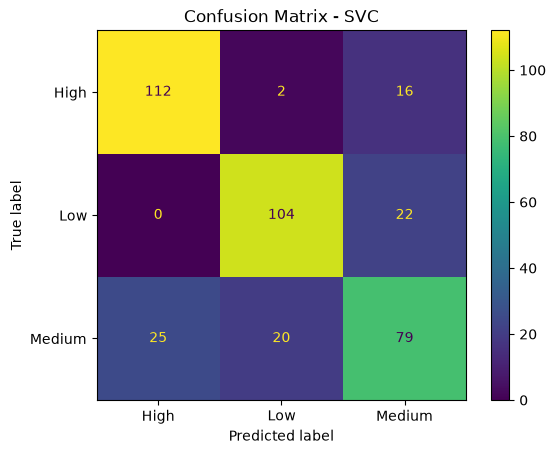

In [48]:
print(classification_report(y_test, y_test_predict))

#  Matrice de confusion
ConfusionMatrixDisplay.from_predictions(
            y_test,
            y_test_predict,
            labels=results_Grid_Search_df.iloc[0]['model'].classes_,
            display_labels=results_Grid_Search_df.iloc[0]['model'].classes_
      )

plt.title(f'Confusion Matrix - {results_Grid_Search_df.iloc[0]['model_name']}')
plt.show()

#### Nous observant que le model fait de fause predictions pour la classe de Medium plus que les autres classes

#### J'ai sélectionné ces quatre algorithmes afin de comparer différentes approches de classification multiclasse. 
- Tout d'abord, j'ai choisi la régression logistique comme modèle de référence, car elle est relativement simple et permet d'établir une première performance de comparaison.
- Ensuite, j'ai sélectionné Decision Tree pour sa capacité à apprendre des règles de décision non linéaires et pour son interprétabilité. J'ai ajouté Random Forest afin d'évaluer si la combinaison de plusieurs arbres permet d'améliorer la généralisation et de réduire le surapprentissage observé avec un arbre individuel. 
- Enfin, j'ai choisi SVC pour tester une approche différente, basée sur la maximisation des marges entre les classes. 
- L'objectif n'était donc pas de supposer qu'un modèle serait meilleur qu'un autre, mais de comparer leurs performances à travers plusieurs métriques adaptées à la classification multiclasse, puis de sélectionner le modèle le plus performant et le plus stable.

In [51]:
import joblib

In [50]:
joblib.dump(results_Grid_Search_df.iloc[0]['model'], '../models/best_model.joblib')

['../models/best_model.joblib']

#### Étape 5 — Orchestration avec Airflow & application Streamlit